In [13]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from regions import Regions
%pip install photutils

from pathlib import Path
from astropy.stats import SigmaClip
from photutils.background import Background2D, MedianBackground
from scipy.ndimage import label, center_of_mass


Note: you may need to restart the kernel to use updated packages.


(4611, 2570)


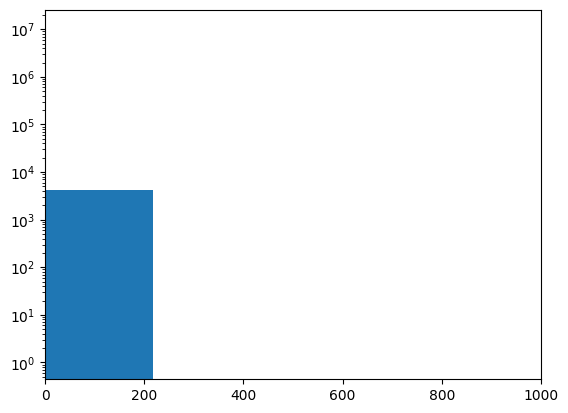

In [4]:
pixel_values = fits.getdata("mosaic.fits")
image = pixel_values.astype(float)

print(image.shape)

x = []

for i in range(len(image)):
    for j in range(len(image[0])):
        pixel_value = image[i,j]
        x.append(pixel_value)

#print(x)

plt.hist(x, bins = 300) #,histtype = "step")
plt.yscale("log")
plt.xlim(0,1000)
#plt.ylim(0,1000)
plt.show()


In [5]:
counts, edges = np.histogram(x,bins=300)
index_maxpeak = np.argmax(counts)
left_edge = edges[index_maxpeak]
right_edge = edges[index_maxpeak+1]
print(left_edge, right_edge)

print(edges[0])


3276.75 3495.2
0.0


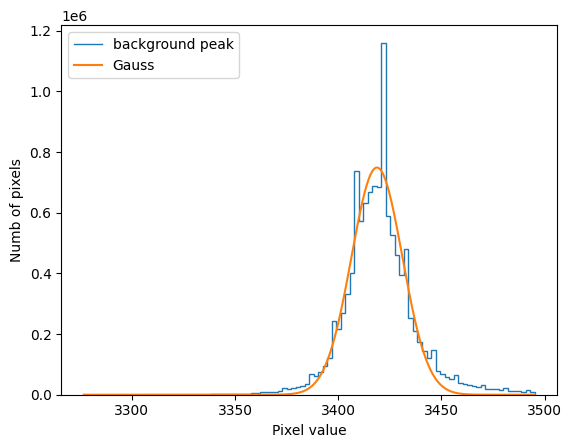

In [6]:
counts, edges = np.histogram(x, bins=100, range=(left_edge, right_edge))

centres = (edges[:-1] + edges[1:]) / 2
def gaussian(v, amplitude, mean, sigma):
    return amplitude * np.exp(-0.5 * ((v - mean) / sigma)**2)

guess = [counts.max(), centres[np.argmax(counts)], 15]

parameters, covariance = curve_fit(gaussian,centres,counts,p0=guess,
            bounds=([0, left_edge, 0.1],[np.inf, right_edge, right_edge - left_edge]))

amplitude, mean, sigma = parameters

v = np.linspace(left_edge, right_edge, 1000)
plt.figure()
plt.stairs(counts, edges, label="background peak")
plt.plot(v, gaussian(v, *parameters), label="Gauss")
plt.xlabel("Pixel value")
plt.ylabel("Numb of pixels")
plt.legend()
plt.show()

In [7]:
background = mean
noise = sigma 
print(mean, sigma)
detection_thres = background + 5 * sigma


3418.7481203844645 12.33658642757741


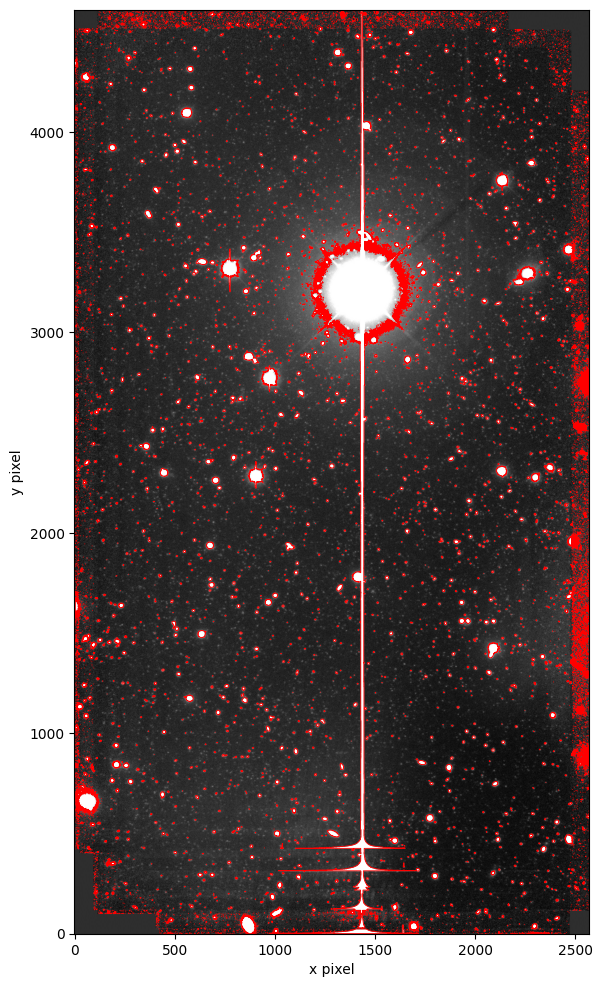

In [8]:
detected_pixels = image > detection_thres

fig, ax = plt.subplots(figsize=(10, 12))

ax.imshow(image,origin="lower",cmap="gray",vmin=mean - 2 * sigma,vmax=mean + 10 * sigma)
ax.contour(detected_pixels.astype(float),levels=[0.5],colors="red",linewidths=0.6)

ax.set_xlabel("x pixel")
ax.set_ylabel("y pixel")
plt.show()

In [9]:
lower = np.min(x)
lower = lower
upper = 3495.2

selected = (image >= lower) & (image <= upper)

y_coords, x_coords = np.where(selected)
selected_values = image[y_coords, x_coords]
print(lower)

0.0


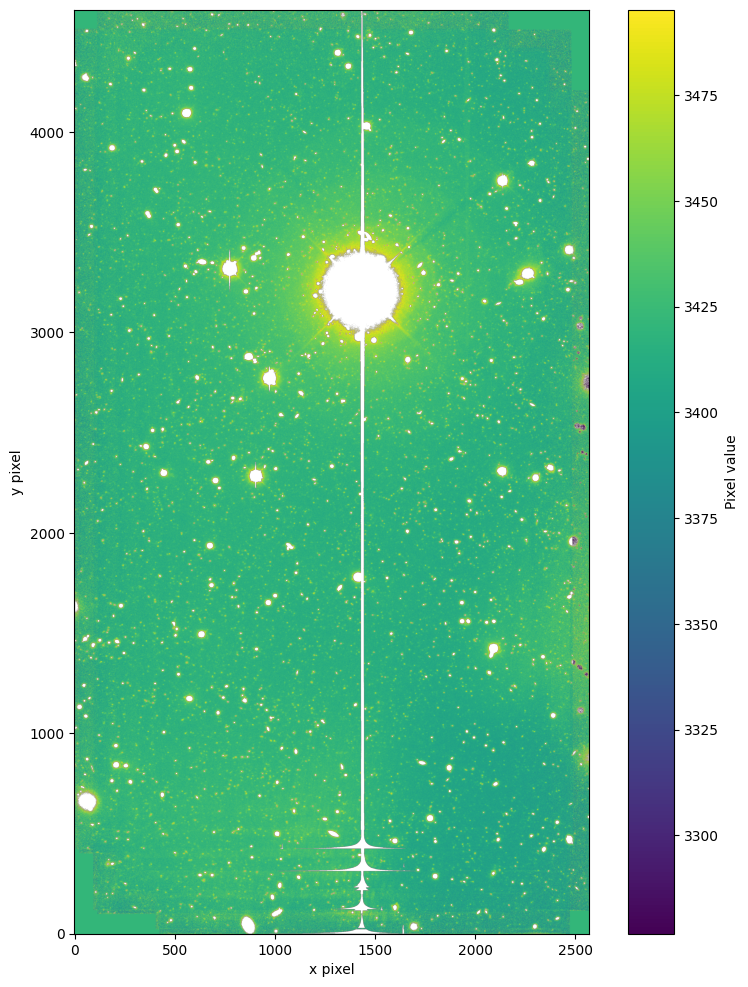

In [10]:
background_map = np.ma.masked_where(~selected, image)

fig, ax = plt.subplots(figsize=(10, 12))

plot = ax.imshow(background_map,origin="lower",cmap="viridis",vmin=3276.75,vmax=upper)

fig.colorbar(plot, ax=ax, label="Pixel value")
ax.set_xlabel("x pixel")
ax.set_ylabel("y pixel")
plt.show()

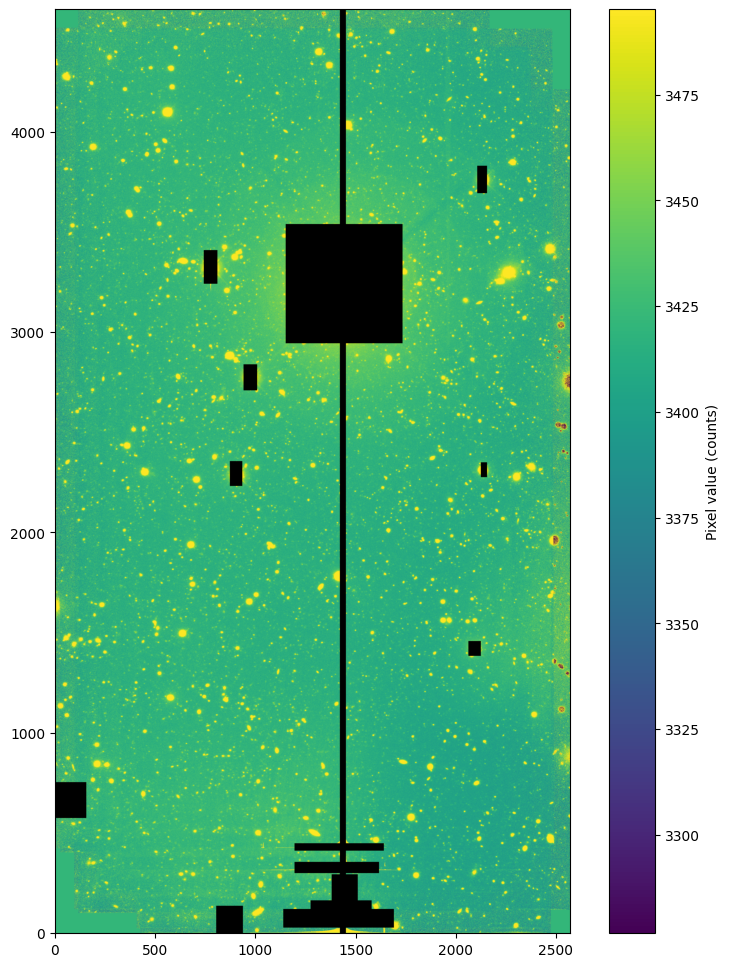

In [29]:
saved_regions = Regions.read("bad_region", format="ds9")

excluded = np.zeros(image.shape, dtype=bool)

for region in saved_regions:
    region_mask = region.to_mask(mode="center").to_image(image.shape)

    if region_mask is not None:
        excluded |= region_mask > 0

display_image = np.ma.masked_where(excluded, image)
colour_map = plt.get_cmap("viridis").copy()
colour_map.set_bad("black")
plt.figure(figsize=(10, 12))
plt.imshow(display_image,origin="lower",cmap=colour_map,vmin=3276.75,vmax=3495.2)
plt.colorbar(label="Pixel value (counts)")
plt.show()